In [1]:
%pip install tensorflow pandas numpy seaborn matplotlib scikit-learn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

I0000 00:00:1794739343.936831   65655 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794739345.009323   65655 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794739347.626356   65655 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Dataset shape: (4998, 141)


/tmp/ipykernel_65655/101923332.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.dropna(inplace=True)


,0,1,2,3,4,5,6,7,8,9,...,131,132,133,134,135,136,137,138,139,140
0,-0.112522,-2.827204,-3.773897,-4.349751,-4.376041,-3.474986,-2.181408,-1.818286,-1.250522,-0.477492,...,0.792168,0.933541,0.796958,0.578621,0.257740,0.228077,0.123431,0.925286,0.193137,1.0
1,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,0.042321,...,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250,1.0
2,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,-0.394229,...,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797,1.0
3,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,-0.965629,...,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564,1.0
4,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,-0.753199,...,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456,1.0


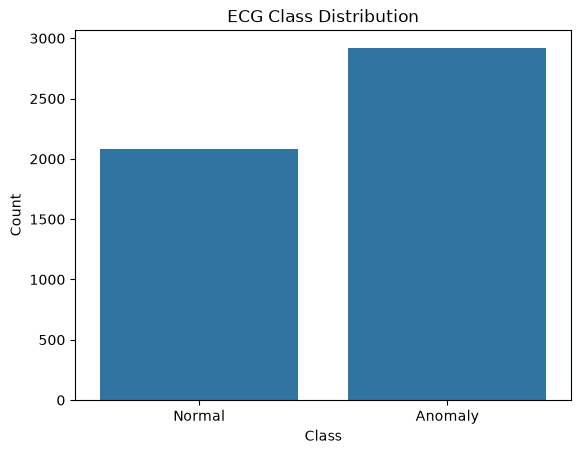

In [3]:
data = pd.read_csv("ecg.csv", header=None)
data.dropna(inplace=True)

print("Dataset shape:", data.shape)
display(data.head())

X = data.iloc[:, :-1].to_numpy(dtype=np.float32)
y = data.iloc[:, -1].to_numpy()

y_binary = (y == 1).astype(int)

sns.countplot(x=y_binary)
plt.xticks([0, 1], ["Normal", "Anomaly"])
plt.title("ECG Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary, test_size=0.2, random_state=42, stratify=y_binary
)

X_train_normal = X_train[y_train == 0]

print("Training data:", X_train_normal.shape)
print("Testing data:", X_test.shape)

Training data: (1663, 140)
Testing data: (1000, 140)


In [5]:
scaler = MinMaxScaler()
X_train_normal_scaled = scaler.fit_transform(X_train_normal)
X_test_scaled = scaler.transform(X_test)

input_dim = X_train_normal_scaled.shape[1]

print("Input features:", input_dim)
print("Normal training shape:", X_train_normal_scaled.shape)
print("Test shape:", X_test_scaled.shape)

Input features: 140
Normal training shape: (1663, 140)
Test shape: (1000, 140)


In [6]:
input_dim = X_train_normal_scaled.shape[1]

autoencoder = models.Sequential([
    layers.Input(shape=(input_dim,)),

    # Encoder
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),

    # Bottleneck
    layers.Dense(8, activation="relu"),

    # Decoder
    layers.Dense(16, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(64, activation="relu"),

    # Reconstructed output
    layers.Dense(input_dim, activation="sigmoid")
])

autoencoder.summary()

E0000 00:00:1794739441.759055   65655 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         9,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 140)            │         9,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,668 (92.45 KB)

 Trainable params: 23,668 (92.45 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

print("Model compiled successfully.")

Model compiled successfully.


Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 281ms/step - loss: 0.0331 - mae: 0.1602 - val_loss: 0.0328 - val_mae: 0.1598
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0322 - mae: 0.1576 - val_loss: 0.0315 - val_mae: 0.1559
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0308 - mae: 0.1529 - val_loss: 0.0294 - val_mae: 0.1492
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0285 - mae: 0.1455 - val_loss: 0.0264 - val_mae: 0.1391
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0253 - mae: 0.1345 - val_loss: 0.0226 - val_mae: 0.1255
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0216 - mae: 0.1206 - val_loss: 0.0187 - val_mae: 0.1106
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0181 - mae: 0.1067 - val_loss: 0.0159 - val_mae: 0.0984
Epoch 8/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0158 - mae: 0.0968 - val_loss: 0.0140 - val_mae: 0.0904
Epoch 9/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0141 - mae: 0.0893 -

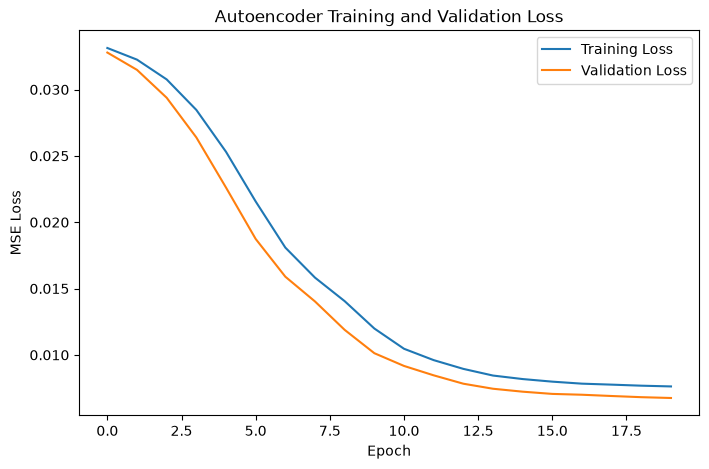

In [8]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_train_normal_scaled,
    X_train_normal_scaled,
    epochs=20,
    batch_size=512,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training and Validation Loss")
plt.legend()
plt.show()

In [9]:
train_predictions = autoencoder.predict(X_train_normal_scaled, verbose=0)
test_predictions = autoencoder.predict(X_test_scaled, verbose=0)

train_errors = np.mean(np.square(X_train_normal_scaled - train_predictions), axis=1)
test_errors = np.mean(np.square(X_test_scaled - test_predictions), axis=1)

threshold = train_errors.mean() + train_errors.std()
print("Reconstruction error threshold:", threshold)

Reconstruction error threshold: 0.016785756


/tmp/ipykernel_65655/4089329459.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Class", loc="upper right")


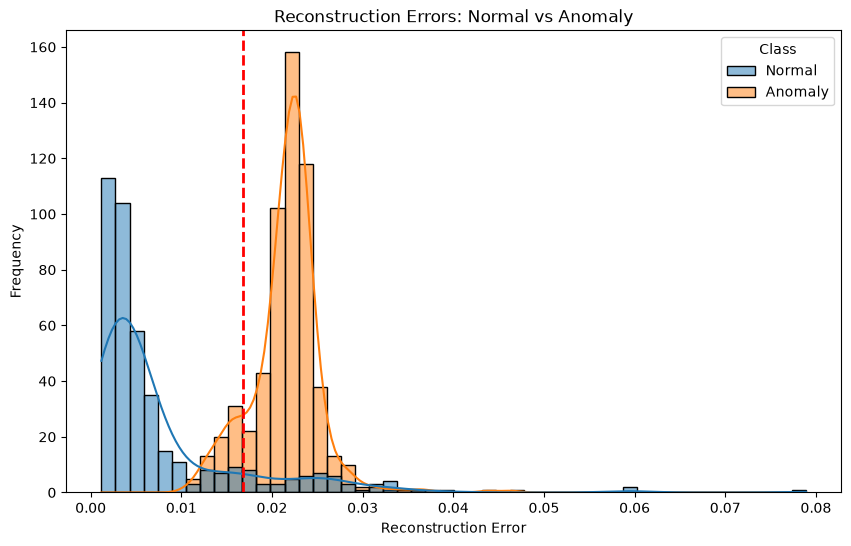

In [10]:
error_df = pd.DataFrame({
    "reconstruction_error": test_errors,
    "true_class": y_test
})
error_df["Class"] = error_df["true_class"].map({0: "Normal", 1: "Anomaly"})

plt.figure(figsize=(10, 6))
plt.legend(title="Class", loc="upper right")
sns.histplot(
    data=error_df,
    x="reconstruction_error",
    hue="Class",
    bins=50,
    kde=True
)
plt.axvline(
    threshold, color="red", linestyle="dashed", linewidth=2,
    label=f"Threshold: {threshold:.4f}"
)
plt.title("Reconstruction Errors: Normal vs Anomaly")
plt.xlabel("Reconstruction Error")
plt.ylabel("Frequency")

plt.show()

Accuracy: 0.879

Classification Report:
              precision    recall  f1-score   support

      Normal       0.84      0.88      0.86       416
     Anomaly       0.91      0.88      0.89       584

    accuracy                           0.88      1000
   macro avg       0.87      0.88      0.88      1000
weighted avg       0.88      0.88      0.88      1000



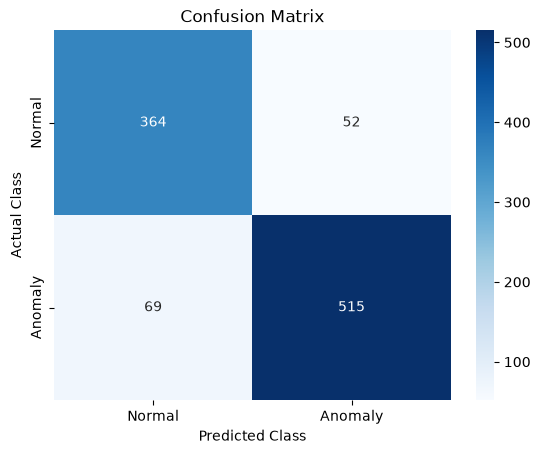

In [11]:
y_pred = (test_errors > threshold).astype(int)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Normal", "Anomaly"]))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Normal", "Anomaly"],
    yticklabels=["Normal", "Anomaly"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()